# Energy density of showers: global and local

Tasks 4 and 5 from Gábor (22/11/2026)

1. **Global density** $\bar\rho_{95} = E_{95}/V_{95}$: the energy inside the smallest set of $5\times5\times10$ cm boxes holding 95% of the event's visible energy, divided by their volume.
2. **3D density profile**: the shower in its own frame is cut into $5\times5\times10$ cm boxes; mean density per box for each particle.
3. **Local density within single showers**: the densest box of each event and the share of energy in "electron-like" dense boxes (candidate EM sub-showers).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, duckdb

# ---------- settings ----------
DATA_DIR = Path(r"C:/Users/Sofia/Desktop/High energy physics thesis/data/extracted_v3/publ-balanced")
FILES = {                       # glob pattern per particle (both seeds are combined)
    "electron": "electron_standalone_*_v3.csv",
    "muon":     "muon_standalone_*_v3.csv",
    "pion":     "pion_standalone_*_v3.csv",
    "proton":   "proton_standalone_*_v3.csv",
}
WORK_DIR = Path("density_work"); WORK_DIR.mkdir(exist_ok=True)
DUCKDB_MEMORY = "3GB"

BOX_XY, BOX_Z = 50.0, 100.0     # mm: 5 x 5 x 10 cm boxes (Gabor)
BOX_L = BOX_XY * BOX_XY * BOX_Z / 1e6   # litres (1 L = 1e6 mm^3) -> 0.25 L
LAYER = 20.5                    # mm, layer pitch
AXIS_R = 50.0                   # mm, "vicinity" of the axis: +-5 cm (Gabor)
P_BINS = [(1, 2), (4, 5), (9, 10), (14, 15), (19, 20)]   # GeV/c, for the maps
COLORS = {"electron": "#2a78d6", "pion": "#e0612a", "proton": "#14976a", "muon": "#b07a00"}
print("box volume:", BOX_L, "L")

box volume: 0.25 L


## Step 1: hits → shower frame → three small tables

Same shower frame as `core.calculate_event_local_coordinates`: the origin is the energy-weighted centre of the event's first hit layer, and the axes are rotated by `incoming_theta`, `incoming_phi`. Boxes are centred on the axis ($x' , y' \in [-25, 25]$ mm is box 0).

Outputs per particle:
* `boxes_*`: energy per event and box $(i_x, i_y, i_z)$
* `layers_*`: energy per event and layer, total and within ±5 cm of the axis
* `events_*`: per event: momentum, total energy, core energy

Event ids combine the file (seed) and `event_number`, since both seeds reuse the same numbers.

In [2]:
def build(name, pattern):
    outs = [WORK_DIR / f"{t}_{name}.parquet" for t in ("boxes", "layers", "events")]
    if all(o.exists() for o in outs):
        print(f"{name}: cached"); return
    files = sorted(DATA_DIR.glob(pattern))
    if not files:
        print(f"{name}: no files match {pattern} -> skipped"); return
    print(f"{name}: {len(files)} file(s) ...", flush=True)
    con = duckdb.connect()
    con.execute(f"SET memory_limit='{DUCKDB_MEMORY}'")
    con.execute("SET preserve_insertion_order=false")
    con.execute(f"SET temp_directory='{(WORK_DIR / 'tmp').as_posix()}'")
    flist = "[" + ",".join(f"'{f.as_posix()}'" for f in files) + "]"
    con.execute(f"""
        CREATE TEMP TABLE raw AS
        SELECT filename AS fn, event_number AS ev, x, y, z, energy AS e,
               incoming_momentum AS p, incoming_theta AS th, incoming_phi AS ph
        FROM read_csv({flist}, filename=true, header=true)
        WHERE energy > 0""")
    con.execute("""
        CREATE TEMP TABLE fid AS
        SELECT fn, row_number() OVER (ORDER BY fn) AS fid FROM (SELECT DISTINCT fn FROM raw)""")
    con.execute("CREATE TEMP TABLE z0 AS SELECT fn, ev, min(z) AS z0 FROM raw GROUP BY fn, ev")
    con.execute("""
        CREATE TEMP TABLE org AS
        SELECT r.fn, r.ev, sum(r.x*r.e)/sum(r.e) AS x0, sum(r.y*r.e)/sum(r.e) AS y0, any_value(z0.z0) AS z0
        FROM raw r JOIN z0 USING (fn, ev) WHERE r.z = z0.z0 GROUP BY r.fn, r.ev""")
    con.execute("""
        CREATE TEMP TABLE loc AS
        SELECT event, p, e, dz,
               dx*cos(th)*cos(ph) + dy*cos(th)*sin(ph) - dz*sin(th) AS xl,
              -dx*sin(ph) + dy*cos(ph)                             AS yl,
               dx*sin(th)*cos(ph) + dy*sin(th)*sin(ph) + dz*cos(th) AS zl
        FROM (SELECT f.fid * 10000000 + r.ev AS event, r.p, r.e, r.th, r.ph,
                     r.x - o.x0 AS dx, r.y - o.y0 AS dy, r.z - o.z0 AS dz
              FROM raw r JOIN org o USING (fn, ev) JOIN fid f USING (fn))""")
    con.execute("DROP TABLE raw")
    con.execute(f"""COPY (
        SELECT event, any_value(p) AS p,
               CAST(floor((xl + {BOX_XY/2}) / {BOX_XY}) AS INTEGER) AS ix,
               CAST(floor((yl + {BOX_XY/2}) / {BOX_XY}) AS INTEGER) AS iy,
               CAST(floor(zl / {BOX_Z}) AS INTEGER) AS iz,
               sum(e) AS E
        FROM loc GROUP BY event, ix, iy, iz) TO '{outs[0].as_posix()}' (FORMAT parquet)""")
    con.execute(f"""COPY (
        SELECT event, CAST(round(dz / {LAYER}) AS INTEGER) AS k,
               sum(e) AS E_layer,
               sum(CASE WHEN xl*xl + yl*yl < {AXIS_R**2} THEN e ELSE 0 END) AS E_axis
        FROM loc GROUP BY event, k) TO '{outs[1].as_posix()}' (FORMAT parquet)""")
    con.execute(f"""COPY (
        SELECT event, any_value(p) AS p, sum(e) AS E, count(*) AS n_hits,
               sum(CASE WHEN xl*xl + yl*yl < {AXIS_R**2} THEN e ELSE 0 END) AS E_core
        FROM loc GROUP BY event) TO '{outs[2].as_posix()}' (FORMAT parquet)""")
    n = con.execute("SELECT count(DISTINCT event) FROM loc").fetchone()[0]
    con.close()
    print(f"   {n} events done", flush=True)

for name, pat in FILES.items():
    build(name, pat)
NAMES = [n for n in FILES if (WORK_DIR / f"events_{n}.parquet").exists()]
print("available:", NAMES)

electron: 2 file(s) ...
   200000 events done
muon: 2 file(s) ...
   200000 events done
pion: 2 file(s) ...
   200000 events done
proton: 2 file(s) ...
   200000 events done
available: ['electron', 'muon', 'pion', 'proton']


## Step 2: global energy density per event

For each event, the boxes are sorted from densest to emptiest and taken until they hold 95% of the visible energy. That gives the containment volume $V_{95}$ (a multiple of 0.25 L) and

$$\bar\rho_{95} = \frac{E_{95}}{V_{95}} \quad [\text{MeV/L, visible energy}].$$

This is model-free and defined event by event, so it can later serve directly as a classification feature. The densest single box, $\rho_{\max}$, is kept as well.

In [3]:
def per_event(name):
    b = pd.read_parquet(WORK_DIR / f"boxes_{name}.parquet", columns=["event", "p", "E"])
    b = b[b.E > 0].sort_values(["event", "E"], ascending=[True, False])
    g = b.groupby("event", sort=False).E
    tot, cum = g.transform("sum"), g.cumsum()
    inside = (cum - b.E) < 0.95 * tot
    ev = b[inside].groupby("event").agg(p=("p", "first"), n95=("E", "size"), E95=("E", "sum"))
    ev["E_tot"] = g.sum()
    ev["E_max_box"] = g.max()
    ev["V95_L"] = ev.n95 * BOX_L
    ev["rho95"] = 1000 * ev.E95 / ev.V95_L            # MeV / L
    ev["rho_max"] = 1000 * ev.E_max_box / BOX_L       # MeV / L
    ev["pbin"] = np.floor(ev.p).astype(int)
    return ev

EV = {n: per_event(n) for n in NAMES}

rows = []
for n, ev in EV.items():
    for pb, g in ev.groupby("pbin"):
        rows.append(dict(particle=n, bin=f"{pb}-{pb+1}", n_events=len(g),
                         E_vis_MeV=1000 * g.E_tot.mean(), V95_L=g.V95_L.mean(),
                         rho95_median=g.rho95.median(),
                         rho_ratio_of_means=1000 * g.E95.mean() / g.V95_L.mean()))
GLOBAL = pd.DataFrame(rows)
GLOBAL.to_csv(WORK_DIR / "global_density_table.csv", index=False)
display(GLOBAL.pivot(index="bin", columns="particle", values="rho95_median").round(2)
        .sort_index(key=lambda s: s.str.split("-").str[0].astype(int)))

particle,electron,muon,pion,proton
bin,,,,
0-1,10.82,8.74,8.44,15.03
1-2,22.78,9.22,9.43,10.21
2-3,32.48,9.61,10.05,8.67
3-4,40.93,9.92,10.73,9.11
4-5,49.15,10.12,12.04,9.80
5-6,56.50,10.21,13.57,10.36
6-7,64.05,10.29,15.14,11.01
7-8,71.31,10.36,16.14,11.90
8-9,77.71,10.33,16.92,12.61


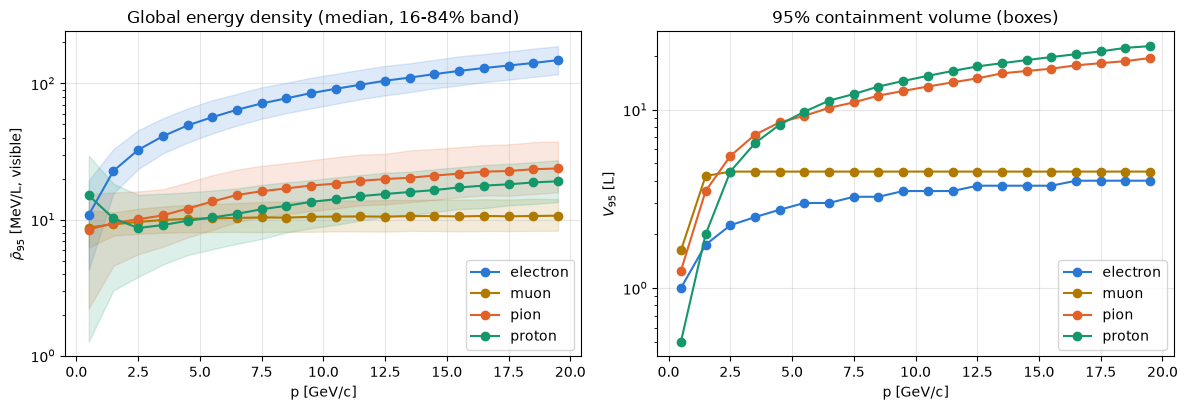

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for n, ev in EV.items():
    s = ev.groupby("pbin").rho95.describe(percentiles=[.16, .5, .84])
    x = s.index + 0.5
    ax[0].plot(x, s["50%"], "o-", color=COLORS[n], label=n)
    ax[0].fill_between(x, s["16%"], s["84%"], color=COLORS[n], alpha=.15)
    v = ev.groupby("pbin").V95_L.median()
    ax[1].plot(v.index + 0.5, v, "o-", color=COLORS[n], label=n)
ax[0].set(yscale="log", xlabel="p [GeV/c]", ylabel=r"$\bar\rho_{95}$ [MeV/L, visible]",
          title="Global energy density (median, 16-84% band)")
ax[1].set(yscale="log", xlabel="p [GeV/c]", ylabel=r"$V_{95}$ [L]", title="95% containment volume (boxes)")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(WORK_DIR / "global_density.pdf"); plt.show()

**Optional: density with the drop volumes.** 

In [5]:
DROP_V = {
    "electron": [51.27, 43.34, 34.33, 25.03, 25.72, 20.31, 32.76, 25.19, 24.03, 23.99,
                 23.01, 20.46, 18.21, 25.39, 20.46, 21.77, 21.91, 21.92, 26.20, 16.61],
    # "pion":   [...],   # from 03_drop_pion
    # "proton": [...],   # from 03_drop_proton
}
rows = []
for n, V in DROP_V.items():
    if n not in EV: continue
    E = EV[n].groupby("pbin").E_tot.mean()
    for pb, v in enumerate(V):
        if pb in E.index:
            rows.append(dict(particle=n, bin=f"{pb}-{pb+1}", V_drop_L=v,
                             E_vis_MeV=1000 * E[pb], rho_drop=0.95 * 1000 * E[pb] / v))
display(pd.DataFrame(rows).round(3))

,particle,bin,V_drop_L,E_vis_MeV,rho_drop
0,electron,0-1,51.27,13.279,0.246
1,electron,1-2,43.34,42.391,0.929
2,electron,2-3,34.33,73.633,2.038
3,electron,3-4,25.03,104.803,3.978
4,electron,4-5,25.72,136.231,5.032
5,electron,5-6,20.31,168.183,7.867
6,electron,6-7,32.76,200.013,5.800
7,electron,7-8,25.19,231.728,8.739
8,electron,8-9,24.03,263.142,10.403
9,electron,9-10,23.99,295.374,11.697


## Step 3: the 3D density profile (5 × 5 × 10 cm boxes)

Mean density of each box over all events of a momentum bin:

$$\rho(i_x,i_y,i_z) = \frac{1}{N_{\rm ev}}\sum_{\rm events}\frac{E_{\rm box}}{0.25\ \text{L}}.$$

Shown: a slice through the axis ($i_y = 0$), the profile along the axis box ($i_x=i_y=0$), and the transverse profile (rings of boxes around the axis).

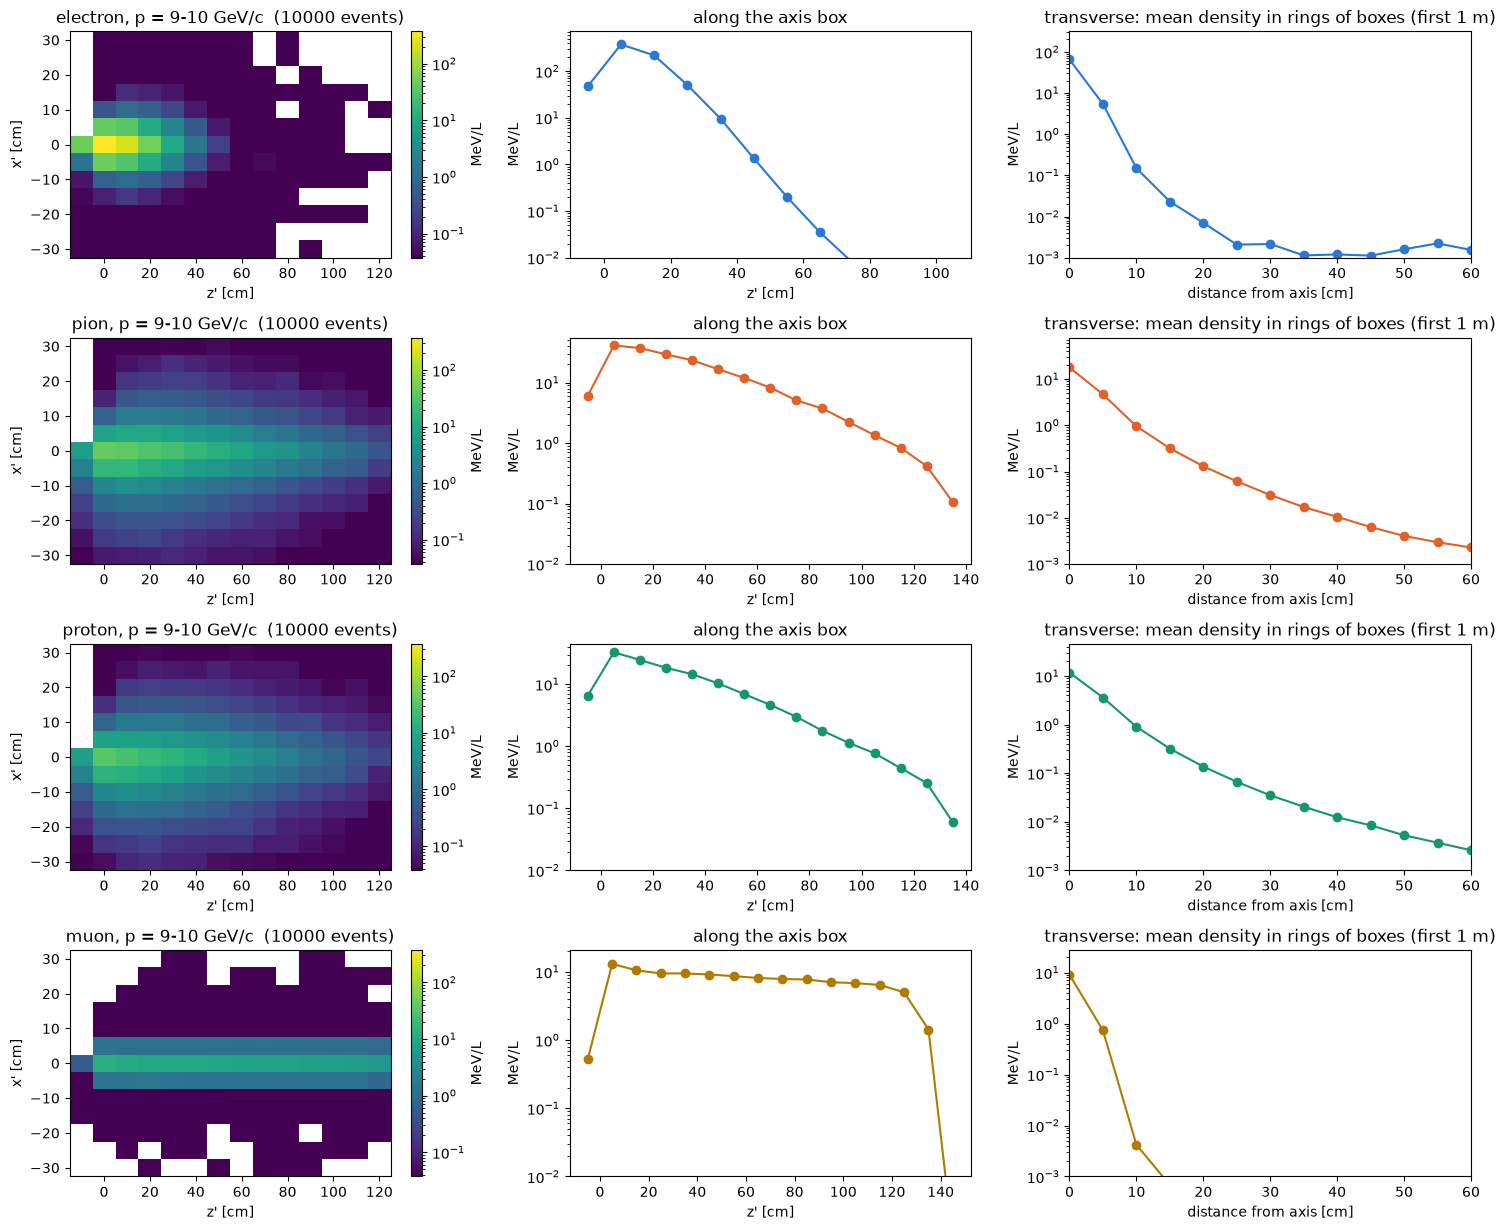

In [13]:
def mean_map(name, lo, hi):
    b = pd.read_parquet(WORK_DIR / f"boxes_{name}.parquet", filters=[("p", ">=", lo), ("p", "<", hi)])
    nev = b.event.nunique()
    m = (b.groupby(["ix", "iy", "iz"]).E.sum() / max(nev, 1) * 1000 / BOX_L).rename("rho").reset_index()
    return m, nev

def plot_profiles(lo, hi, names=("electron", "pion", "proton", "muon")):
    names = [n for n in names if n in NAMES]
    fig, ax = plt.subplots(len(names), 3, figsize=(15, 3.1 * len(names)), squeeze=False)
    vmax = None
    for row, n in enumerate(names):
        m, nev = mean_map(n, lo, hi)
        sl = m[m.iy == 0].pivot(index="ix", columns="iz", values="rho")
        sl = sl.reindex(index=range(-6, 7), columns=range(-1, 13)).fillna(0)
        vmax = vmax or max(sl.values.max(), 1e-9)
        im = ax[row, 0].pcolormesh(sl.columns * BOX_Z / 10, sl.index * BOX_XY / 10, sl.values,
                                   norm=plt.matplotlib.colors.LogNorm(vmin=vmax * 1e-4, vmax=vmax), shading="nearest")
        ax[row, 0].set(title=f"{n}, p = {lo}-{hi} GeV/c  ({nev} events)", xlabel="z' [cm]", ylabel="x' [cm]")
        fig.colorbar(im, ax=ax[row, 0], label="MeV/L")
        a = m[(m.ix == 0) & (m.iy == 0)].sort_values("iz")
        ax[row, 1].semilogy(a.iz * BOX_Z / 10 + BOX_Z / 20, a.rho, "o-", color=COLORS[n])
        ax[row, 1].set(title="along the axis box", xlabel="z' [cm]", ylabel="MeV/L")
        m["ring"] = np.maximum(m.ix.abs(), m.iy.abs())
        d = m[(m.iz >= 0) & (m.iz < 10)]                                   # first 1 m of depth
        n_geo = lambda k: 1 if k == 0 else 8 * k                            # boxes in ring k
        rg = d.groupby("ring").rho.sum() / [n_geo(k) * 10 for k in d.groupby("ring").rho.sum().index]
        ax[row, 2].semilogy(rg.index * BOX_XY / 10, rg.values, "o-", color=COLORS[n])
        ax[row, 2].set(title="transverse: mean density in rings of boxes (first 1 m)", xlabel="distance from axis [cm]", ylabel="MeV/L")
    for a in ax[:, 2]: a.set_xlim(0, 60); a.set_ylim(1e-3, None)
    for a in ax[:, 1]: a.set_ylim(1e-2, None)
    fig.tight_layout(); fig.savefig(WORK_DIR / f"density_profile_{lo}_{hi}GeV.pdf"); plt.show()

plot_profiles(9, 10)

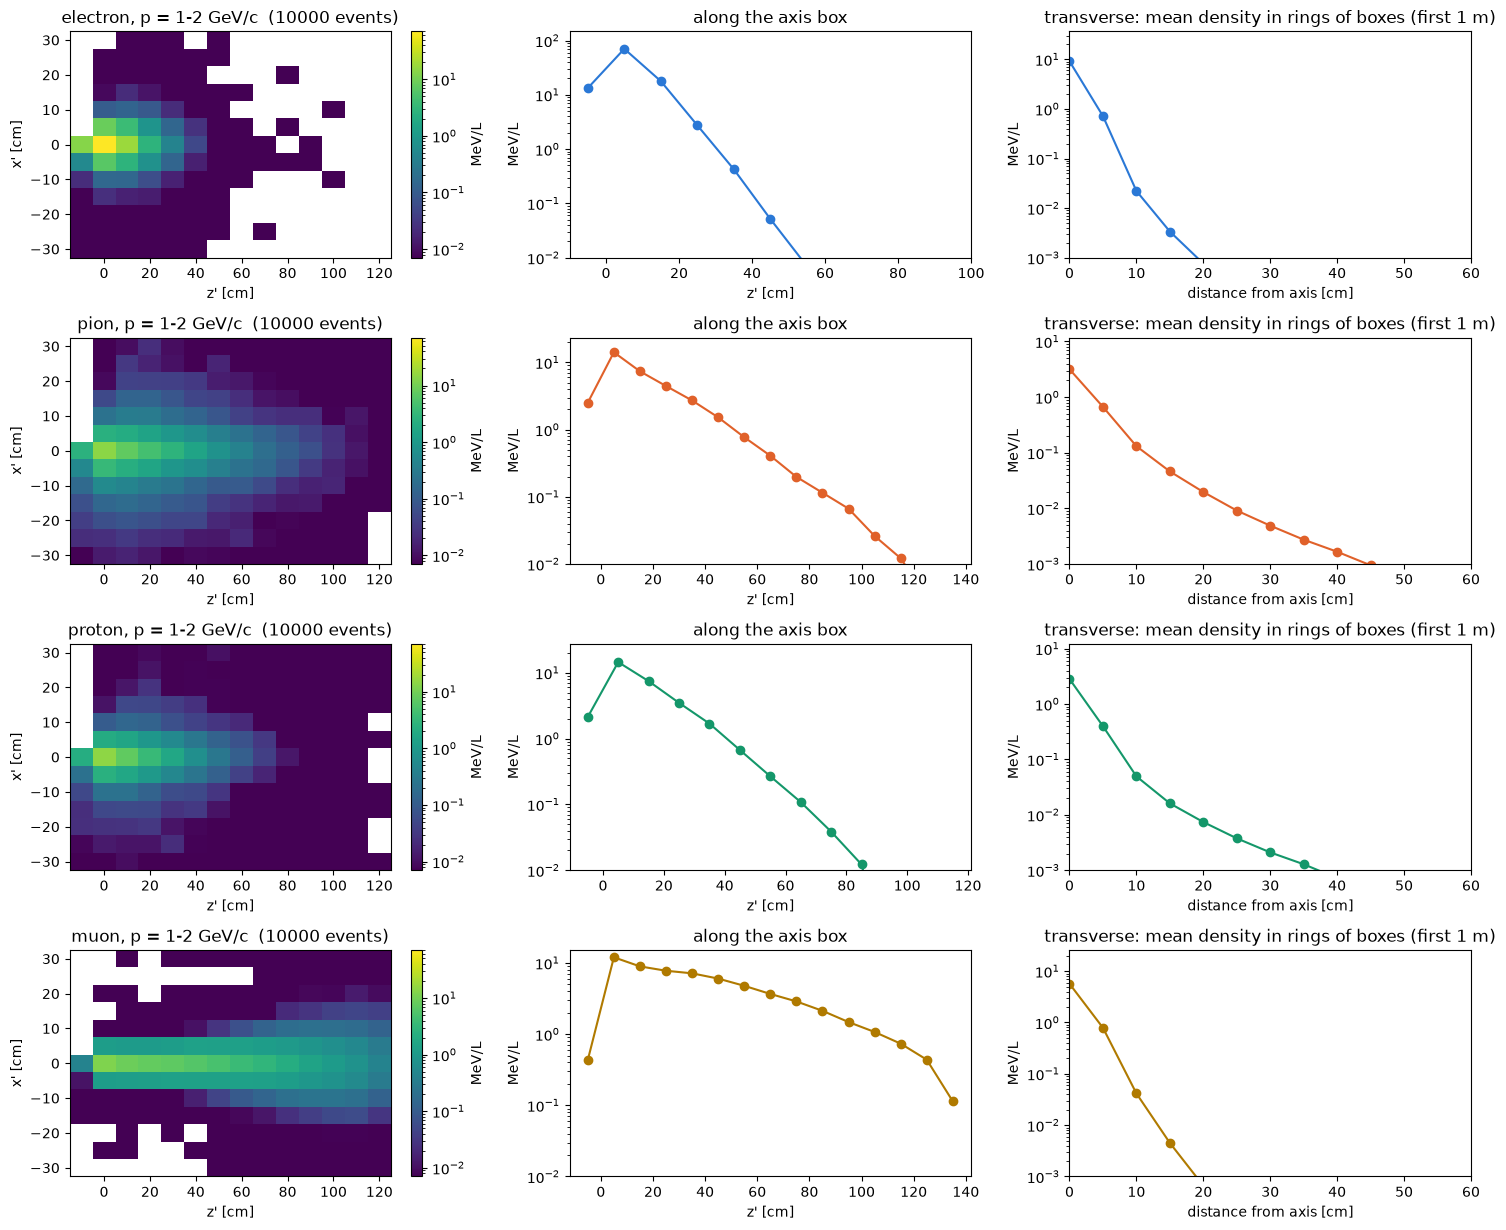

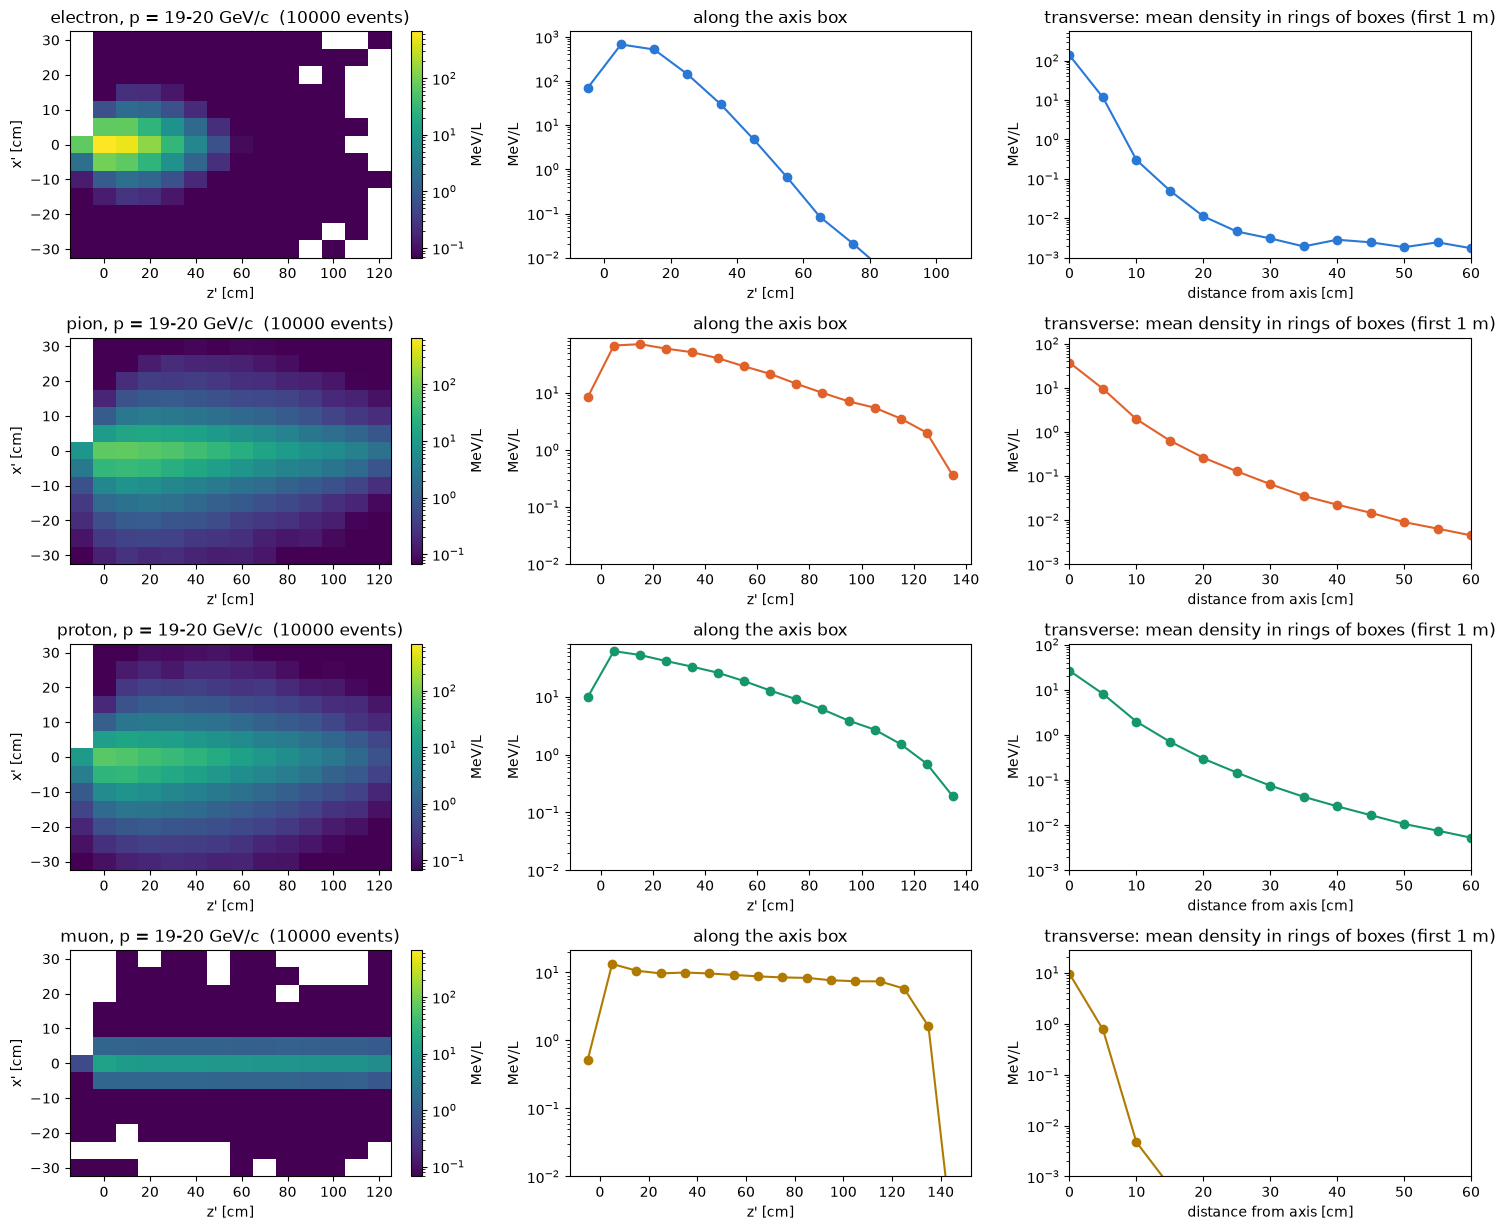

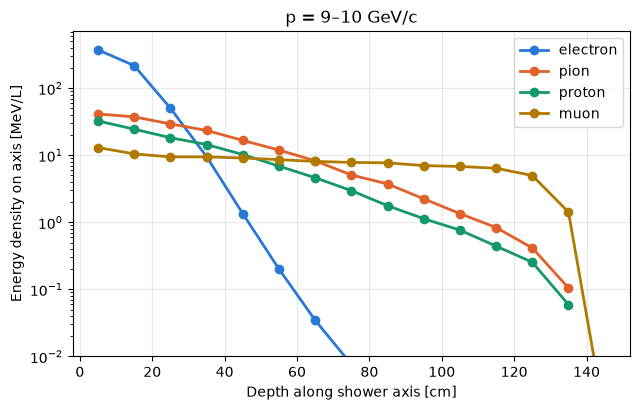

In [15]:
for lo, hi in [(1, 2), (19, 20)]:      # other momenta; add more from P_BINS if useful
    plot_profiles(lo, hi)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n in ["electron", "pion", "proton", "muon"]:
    m, nev = mean_map(n, 9, 10)
    a = m[(m.ix == 0) & (m.iy == 0) & (m.iz >= 0)].sort_values("iz")
    ax.semilogy(a.iz * BOX_Z / 10 + BOX_Z / 20, a.rho, "o-", color=COLORS[n], label=n, lw=2)
ax.set(xlabel="Depth along shower axis [cm]", ylabel="Energy density on axis [MeV/L]",
       title="p = 9–10 GeV/c", ylim=(1e-2, None))
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(WORK_DIR / "axis_density_overlay_9_10GeV.pdf"); plt.show()

## Step 4: local density inside single showers

An electron shower is dense; a hadron shower is dilute on average. But if a hadron shower contains an EM sub-shower ($\pi^0\to\gamma\gamma$), some of its boxes should reach electron-like densities.

Per event:
* $\rho_{\max}$: the densest box;
* $f_{\rm dense}$: the share of the event's energy in boxes denser than an **electron-like threshold**, set to the 10th percentile of the electrons' $\rho_{\max}$ in the same momentum bin (so 90% of electrons pass it).

p=4-5: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.463
p=4-5: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=4-5: pion     share of events with an electron-like box: 13.2%   mean f_dense = 0.044
p=4-5: proton   share of events with an electron-like box:  7.4%   mean f_dense = 0.029


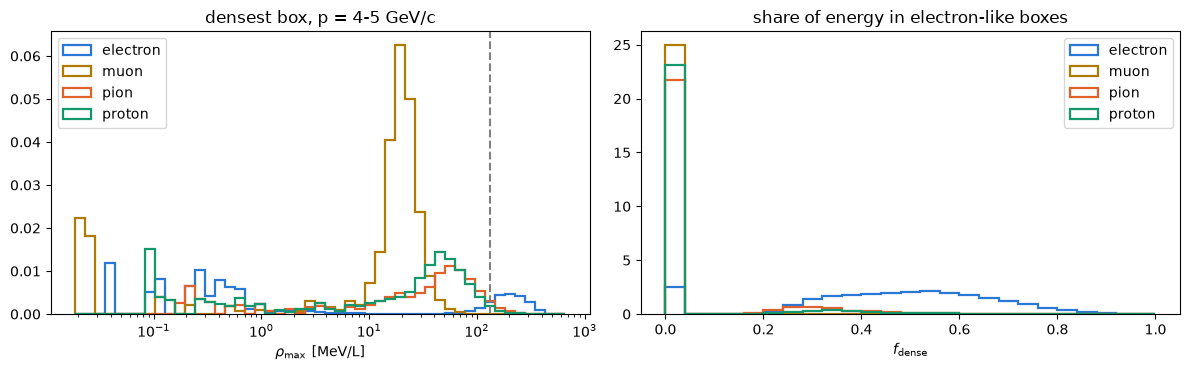

p=9-10: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.447
p=9-10: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=9-10: pion     share of events with an electron-like box:  9.9%   mean f_dense = 0.033
p=9-10: proton   share of events with an electron-like box:  3.4%   mean f_dense = 0.012


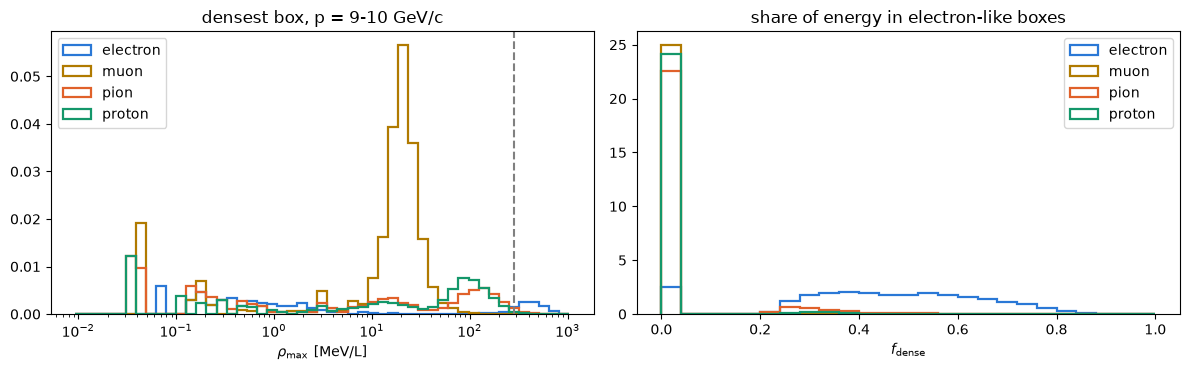

p=19-20: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.439
p=19-20: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=19-20: pion     share of events with an electron-like box:  8.1%   mean f_dense = 0.027
p=19-20: proton   share of events with an electron-like box:  1.6%   mean f_dense = 0.005


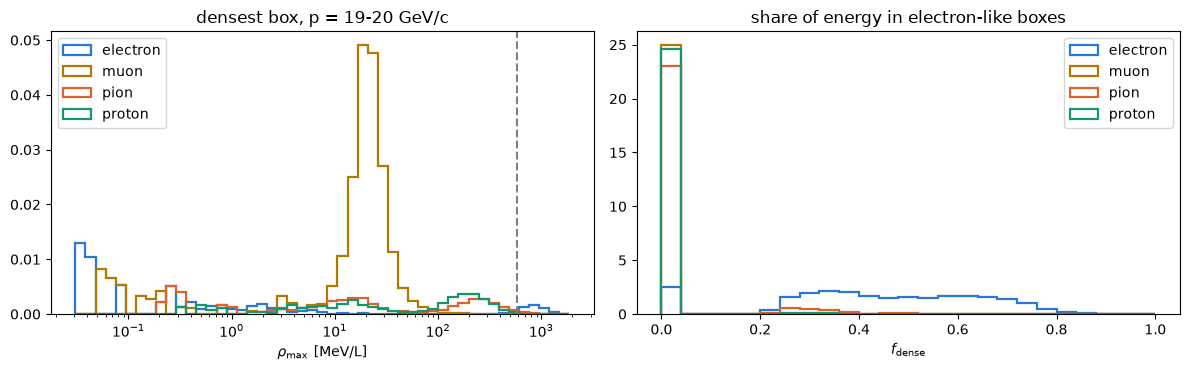

In [8]:
def local_features(lo, hi, q=0.10):
    thr = EV["electron"].query("@lo <= p < @hi").rho_max.quantile(q)
    out = {}
    for n in NAMES:
        b = pd.read_parquet(WORK_DIR / f"boxes_{n}.parquet", columns=["event", "p", "E"],
                            filters=[("p", ">=", lo), ("p", "<", hi)])
        b["rho"] = 1000 * b.E / BOX_L
        g = b.groupby("event")
        f = pd.DataFrame({"rho_max": g.rho.max(),
                          "f_dense": b.E.where(b.rho >= thr, 0).groupby(b.event).sum() / g.E.sum()})
        out[n] = f
    return thr, out

for lo, hi in [(4, 5), (9, 10), (19, 20)]:
    thr, F = local_features(lo, hi)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    bins = np.logspace(np.log10(max(min(f.rho_max.min() for f in F.values()), 1e-3)),
                       np.log10(max(f.rho_max.max() for f in F.values())), 50)
    for n, f in F.items():
        ax[0].hist(f.rho_max, bins=bins, histtype="step", density=True, color=COLORS[n], label=n, lw=1.6)
        ax[1].hist(f.f_dense, bins=np.linspace(0, 1, 26), histtype="step", density=True, color=COLORS[n], label=n, lw=1.6)
        print(f"p={lo}-{hi}: {n:8s} share of events with an electron-like box: {np.mean(f.rho_max >= thr):5.1%}"
              f"   mean f_dense = {f.f_dense.mean():.3f}")
    ax[0].axvline(thr, ls="--", c="grey"); ax[0].set(xscale="log", xlabel=r"$\rho_{\max}$ [MeV/L]", title=f"densest box, p = {lo}-{hi} GeV/c")
    ax[1].set(xlabel=r"$f_{\rm dense}$", title="share of energy in electron-like boxes")
    for a in ax: a.legend()
    fig.tight_layout(); fig.savefig(WORK_DIR / f"local_density_{lo}_{hi}GeV.pdf"); plt.show()